In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Create an array of

In [24]:
df=pd.DataFrame({
    'Hours Studied':[2,4,6,8],
    'Test Score':[1,3,5,7],
},index=['A','B','C','D'])
df.head()

,Hours Studied,Test Score
A,2,1
B,4,3
C,6,5
D,8,7


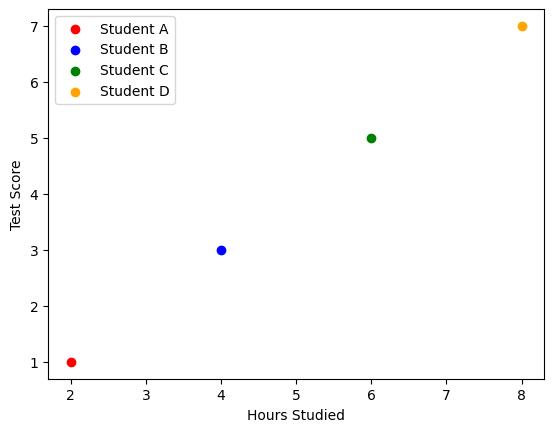

In [25]:
plt.scatter(df['Hours Studied'].iloc[0], df['Test Score'].iloc[0],
            color='red', label='Student A')

plt.scatter(df['Hours Studied'].iloc[1], df['Test Score'].iloc[1],
            color='blue', label='Student B')

plt.scatter(df['Hours Studied'].iloc[2], df['Test Score'].iloc[2],
            color='green', label='Student C')

plt.scatter(df['Hours Studied'].iloc[3], df['Test Score'].iloc[3],
            color='orange', label='Student D')

plt.xlabel('Hours Studied')
plt.ylabel('Test Score')
plt.legend()
plt.show()

In [26]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [27]:
scaler.fit(df)

StandardScaler()

In [28]:
scaled_data=scaler.transform(df)

In [29]:
scaled_data

array([[-1.34164079, -1.34164079],
       [-0.4472136 , -0.4472136 ],
       [ 0.4472136 ,  0.4472136 ],
       [ 1.34164079,  1.34164079]])

In [30]:
scaled_data=pd.DataFrame(scaled_data,columns=['Hours Studied','Test Score'])
scaled_data
# the total sum of each column should be upto 0

,Hours Studied,Test Score
0,-1.341641,-1.341641
1,-0.447214,-0.447214
2,0.447214,0.447214
3,1.341641,1.341641


Before and after scaling visualization

In [31]:
print(scaled_data.columns)

Index(['Hours Studied', 'Test Score'], dtype='object')


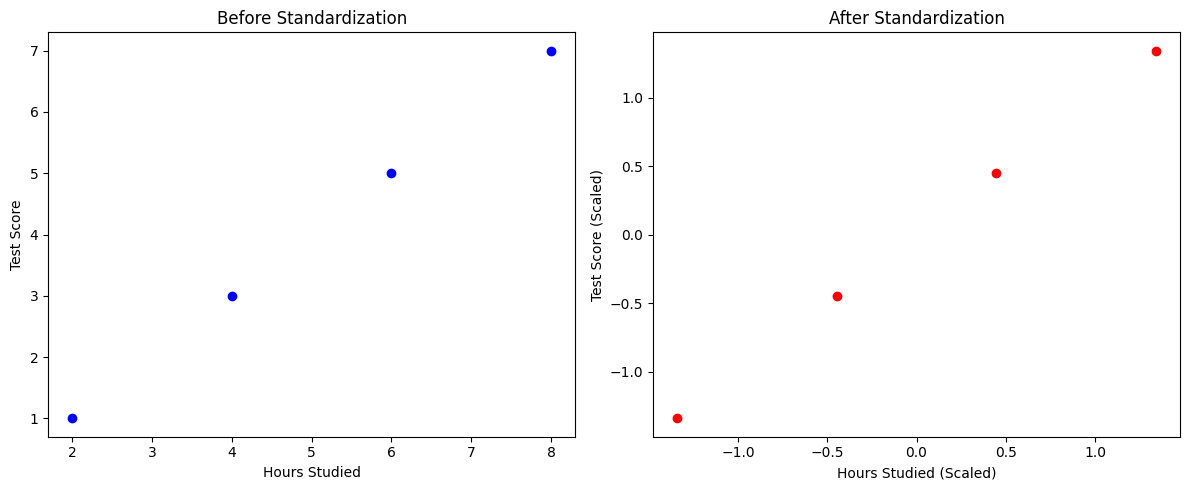

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original data
axes[0].scatter(df['Hours Studied'], df['Test Score'],color='blue')
axes[0].set_title('Before Standardization')
axes[0].set_xlabel('Hours Studied')
axes[0].set_ylabel('Test Score')

# Scaled data
axes[1].scatter(
    scaled_data['Hours Studied'],
    scaled_data['Test Score'],color='red'
)
axes[1].set_title('After Standardization')
axes[1].set_xlabel('Hours Studied (Scaled)')
axes[1].set_ylabel('Test Score (Scaled)')

plt.tight_layout()
plt.show()

### Now lets form covariance matrix

In [35]:
cov_matrix=scaled_data.cov()
cov_matrix

,Hours Studied,Test Score
Hours Studied,1.333333,1.333333
Test Score,1.333333,1.333333


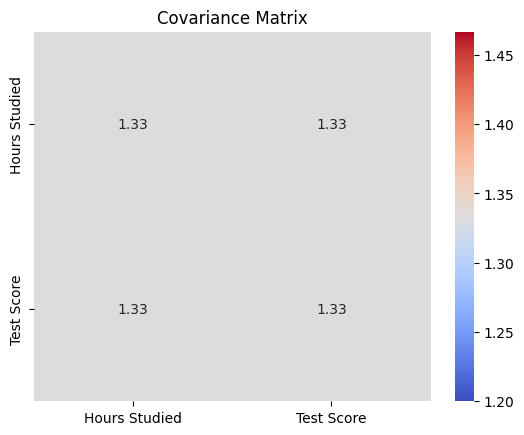

In [36]:
import seaborn as sns
sns.heatmap(cov_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Covariance Matrix')
plt.show()

###Now calculate eigen values and eigen vectors

In [40]:
eigenvalues,eigenvectors=np.linalg.eig(cov_matrix)
print("Eigenvalues:")
for i, value in enumerate(eigenvalues):
    print(f"PC{i+1}\t{value:.4f}")

print("\nEigenvectors:")
print(f"{'':<10}{'PC1':>12}{'PC2':>12}")

for i, vector in enumerate(eigenvectors):
    print(f"{'Feature '+str(i+1):<10}{vector[0]:>12.4f}{vector[1]:>12.4f}")

Eigenvalues:
PC1	2.6667
PC2	0.0000

Eigenvectors:
                   PC1         PC2
Feature 1       0.7071     -0.7071
Feature 2       0.7071      0.7071


Visualizing eigen values and eigen vectors

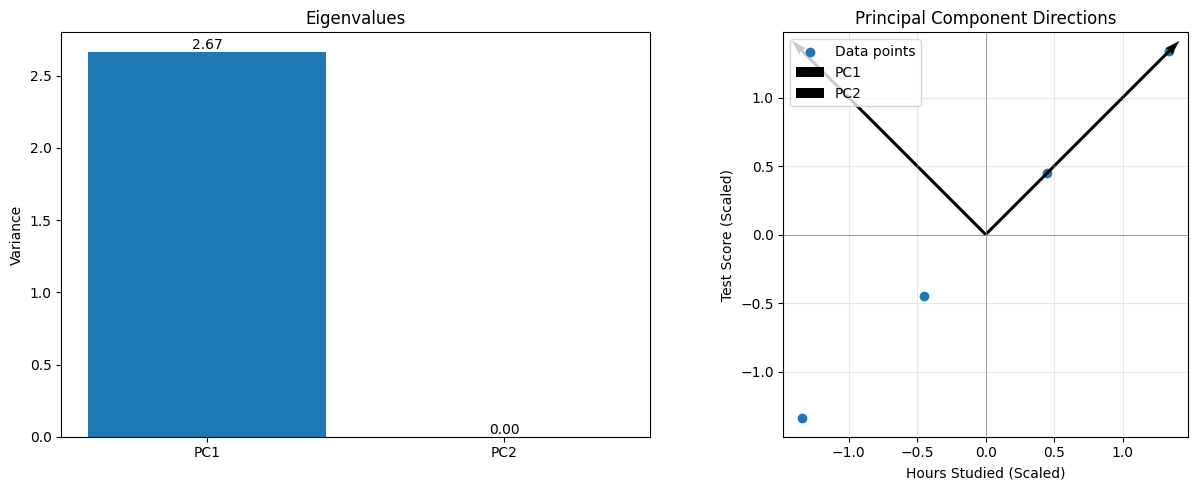

In [41]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Eigenvalues
axes[0].bar(['PC1', 'PC2'], eigenvalues)
axes[0].set_title('Eigenvalues')
axes[0].set_ylabel('Variance')
axes[0].set_ylim(bottom=0)

for i, value in enumerate(eigenvalues):
    axes[0].text(i, value, f'{value:.2f}', ha='center', va='bottom')

# 2. Standardized data + eigenvectors
axes[1].scatter(
    scaled_data['Hours Studied'],
    scaled_data['Test Score'],
    label='Data points'
)

# Draw eigenvector directions from origin
for i, name in enumerate(['PC1', 'PC2']):
    vector = eigenvectors[:, i]
    axes[1].quiver(
        0, 0,
        vector[0] * 2,
        vector[1] * 2,
        angles='xy',
        scale_units='xy',
        scale=1,
        label=name
    )

axes[1].axhline(0, color='gray', linewidth=0.5)
axes[1].axvline(0, color='gray', linewidth=0.5)
axes[1].set_xlabel('Hours Studied (Scaled)')
axes[1].set_ylabel('Test Score (Scaled)')
axes[1].set_title('Principal Component Directions')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


Calculating variance ratio to see which PC covers maximum variance

In [43]:
var_ratio=(eigenvalues/np.sum(eigenvalues))*100
print(var_ratio)

[100.   0.]


Now select PC1 which covers maximum variance

In [46]:
PC1=eigenvectors[:,0]
print(PC1)

[0.70710678 0.70710678]


PROJECT DATA ON PC1

@ is used for matrix multiplication here

2 features are reduced to 1 feature

In [47]:
PCA_data=scaled_data @ PC1
print(PCA_data)

0   -1.897367
1   -0.632456
2    0.632456
3    1.897367
dtype: float64


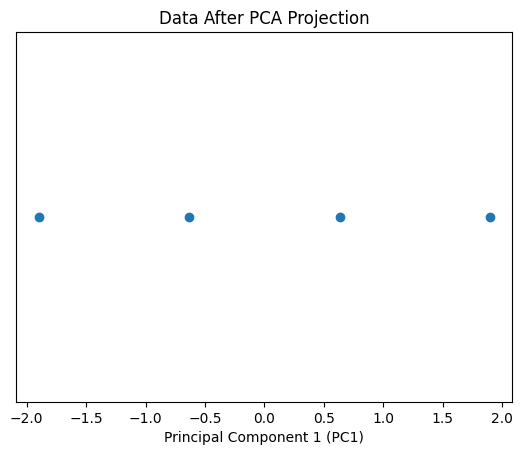

In [52]:
plt.scatter(PCA_data, [0]*len(PCA_data))

plt.xlabel('Principal Component 1 (PC1)')
plt.title('Data After PCA Projection')
plt.yticks([])

plt.show()